In [ ]:
import pandas as pd

# 1. Memuat dataset ke dalam DataFrame
df = pd.read_csv('bitcoin_dataset.csv')

# 2. Menampilkan 5 baris pertama data
print("=== 5 BARIS PERTAMA DATASET ===")
display(df.head())

# 3. Menampilkan informasi dimensi dan tipe data
print("\n=== INFORMASI STRUKTUR DATA ===")
df.info()

=== 5 BARIS PERTAMA DATASET ===


,Date,Open,High,Low,Close,Adj Close,Volume
0,2014-09-17,465.864014,468.174011,452.421997,457.334015,457.334015,21056800
1,2014-09-18,456.859985,456.859985,413.104004,424.440002,424.440002,34483200
2,2014-09-19,424.102997,427.834991,384.532013,394.795990,394.795990,37919700
3,2014-09-20,394.673004,423.295990,389.882996,408.903992,408.903992,36863600
4,2014-09-21,408.084991,412.425995,393.181000,398.821014,398.821014,26580100



=== INFORMASI STRUKTUR DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4280 entries, 0 to 4279
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       4280 non-null   object 
 1   Open       4280 non-null   float64
 2   High       4280 non-null   float64
 3   Low        4280 non-null   float64
 4   Close      4280 non-null   float64
 5   Adj Close  4280 non-null   float64
 6   Volume     4280 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 234.2+ KB


In [ ]:
# 1. Transformasi Format Waktu dan Pengurutan (Sorting)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')

# 2. Rekayasa Fitur (Feature Engineering) Dasar
df['Daily_Volatility'] = df['High'] - df['Low']

# Menampilkan informasi untuk konfirmasi
print("=== VERIFIKASI TIPE DATA ===")
print(df[['Date', 'Daily_Volatility']].dtypes)

=== VERIFIKASI TIPE DATA ===
Date                datetime64[ns]
Daily_Volatility           float64
dtype: object


In [ ]:
# 3. Pengecekan Missing Values
print("=== PENGECEKAN MISSING VALUES ===")
print(df.isnull().sum())

# 4. Pengecekan Data Duplikat
print("\n=== PENGECEKAN DATA DUPLIKAT ===")
print(f"Jumlah baris transaksi ganda (duplikat): {df.duplicated().sum()}")

# 5. Menampilkan wujud data yang sudah bersih
print("\n=== HASIL AKHIR PREPROCESSING ===")
display(df[['Date', 'Close', 'Daily_Volatility', 'Volume']].head())

=== PENGECEKAN MISSING VALUES ===
Date                0
Open                0
High                0
Low                 0
Close               0
Adj Close           0
Volume              0
Daily_Volatility    0
dtype: int64

=== PENGECEKAN DATA DUPLIKAT ===
Jumlah baris transaksi ganda (duplikat): 0

=== HASIL AKHIR PREPROCESSING ===


,Date,Close,Daily_Volatility,Volume
0,2014-09-17,457.334015,15.752014,21056800
1,2014-09-18,424.440002,43.755981,34483200
2,2014-09-19,394.795990,43.302979,37919700
3,2014-09-20,408.903992,33.412994,36863600
4,2014-09-21,398.821014,19.244995,26580100


In [ ]:
# 1. Import library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tema grafik agar tampilannya elegan seperti paper akademis
sns.set_theme(style="whitegrid")

# 2. Menampilkan Statistik Deskriptif
print("=== STATISTIK DESKRIPTIF (NILAI MIN, MAX, RATA-RATA) ===")
display(df[['Close', 'Volume', 'Daily_Volatility']].describe())

=== STATISTIK DESKRIPTIF (NILAI MIN, MAX, RATA-RATA) ===


,Close,Volume,Daily_Volatility
count,4280.000000,4.280000e+03,4280.000000
mean,28636.451670,2.230348e+10,1168.575027
std,32442.454923,2.294359e+10,1564.968724
min,178.102997,5.914570e+06,1.028000
25%,3458.813721,1.676575e+09,84.018372
50%,11564.331543,1.802679e+10,487.917603
75%,46446.924805,3.446429e+10,1759.401367
max,124752.531250,3.509679e+11,17927.250000


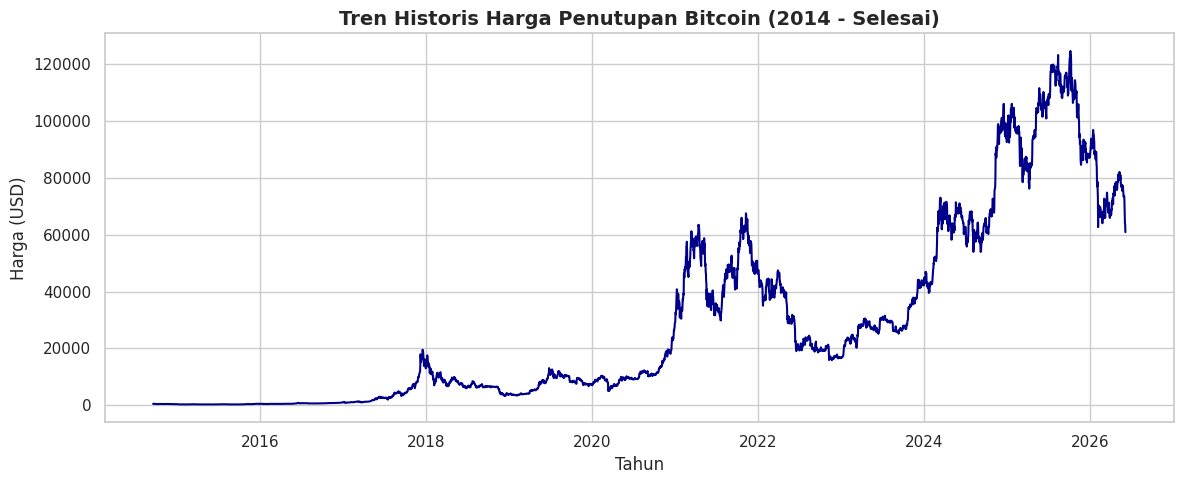

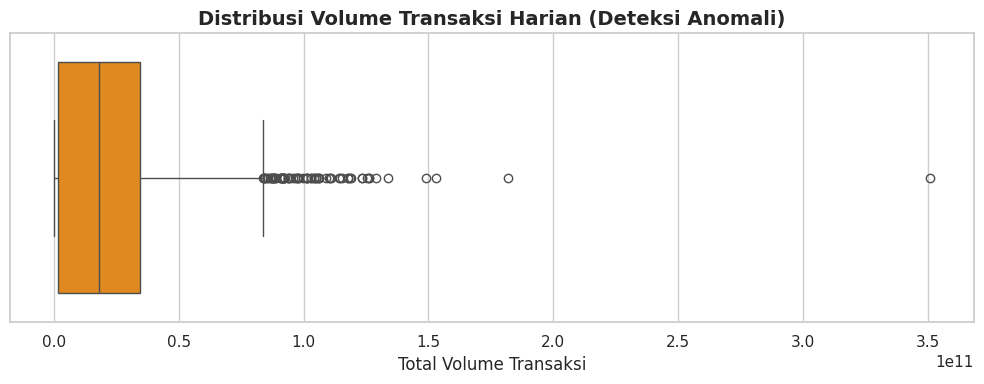

In [ ]:
# 1. Visualisasi Tren Historis Harga Penutupan (Line Chart)
plt.figure(figsize=(12, 5))
sns.lineplot(data=df, x='Date', y='Close', color='darkblue', linewidth=1.5)
plt.title('Tren Historis Harga Penutupan Bitcoin (2014 - Selesai)', fontsize=14, fontweight='bold')
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Harga (USD)', fontsize=12)
plt.tight_layout()
plt.show()

print("\n" + "="*50 + "\n") # Pemisah visual di Colab

# 2. Visualisasi Deteksi Anomali Volume (Boxplot)
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Volume'], color='darkorange')
plt.title('Distribusi Volume Transaksi Harian (Deteksi Anomali)', fontsize=14, fontweight='bold')
plt.xlabel('Total Volume Transaksi', fontsize=12)
plt.tight_layout()
plt.show()

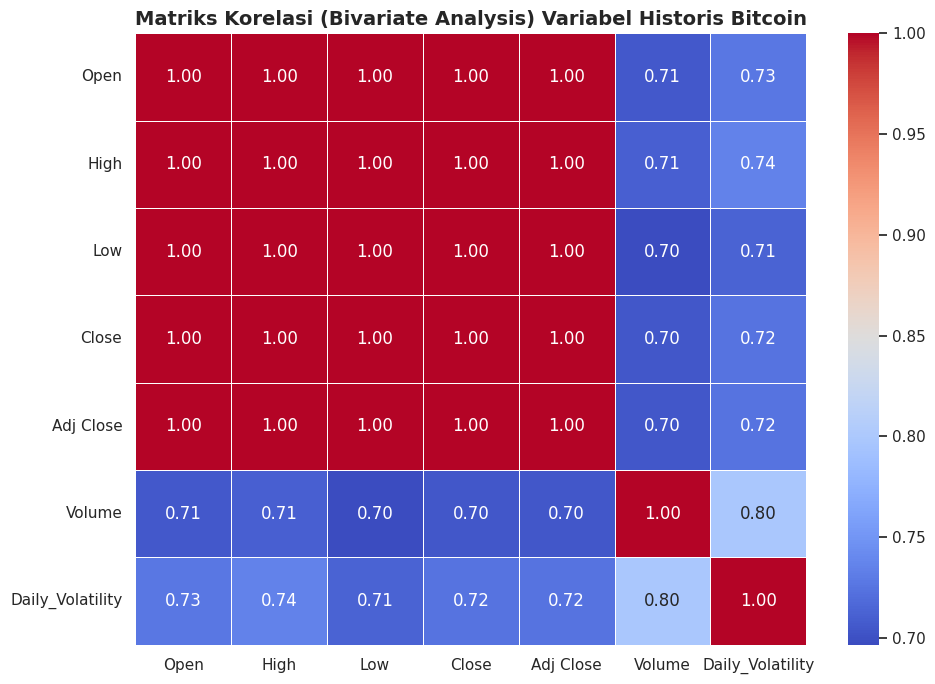

In [ ]:
# 1. Import library
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Membuat Heatmap Matriks Korelasi (Pearson)
plt.figure(figsize=(10, 7))

# Menghitung korelasi khusus untuk kolom numerik agar tidak error karena kolom Date
correlation_matrix = df.corr(numeric_only=True)

# Membuat visualisasi Heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

plt.title('Matriks Korelasi (Bivariate Analysis) Variabel Historis Bitcoin', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# 1. Memuat dataset yang baru saja di-upload
df = pd.read_csv('bitcoin_dataset.csv')

# 2. Transformasi Tanggal dan Pengurutan Kronologis
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')

# 3. Feature Engineering (Membuat variabel Volatilitas Harian)
df['Daily_Volatility'] = df['High'] - df['Low']

print("=== TAHAP PREPROCESSING BERHASIL ===")
print(f"Data berhasil dimuat kembali. Total: {df.shape[0]} baris.")

=== TAHAP PREPROCESSING BERHASIL ===
Data berhasil dimuat kembali. Total: 4280 baris.


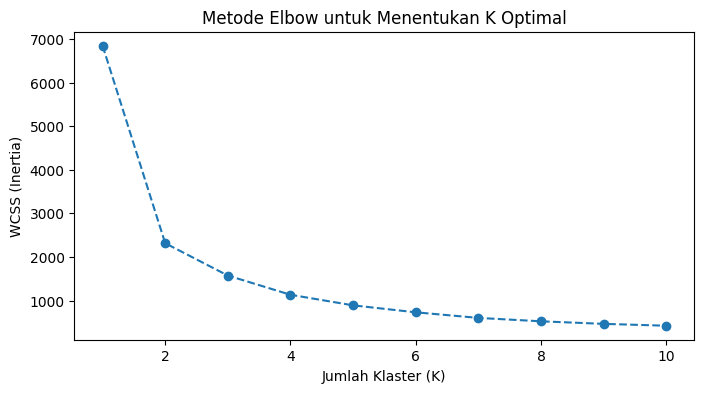

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt # Ensure plt is imported for visualization

# 1. Memilih fitur utama untuk klasterisasi risiko (copied from FtlTzX0vRwCw)
features = ['Close', 'Daily_Volatility']
X = df[features]

# 2. Split Data (80% Training, 20% Testing) (copied from FtlTzX0vRwCw)
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

# 3. Scaling (Standardisasi data agar adil) (copied from FtlTzX0vRwCw)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Mencari jumlah K optimal dengan Elbow Method
wcss = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_train_scaled)
    wcss.append(kmeans.inertia_)

# Visualisasi Elbow Method
plt.figure(figsize=(8, 4))
plt.plot(K_range, wcss, marker='o', linestyle='--')
plt.title('Metode Elbow untuk Menentukan K Optimal')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('WCSS (Inertia)')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Memilih fitur utama untuk klasterisasi risiko
features = ['Close', 'Daily_Volatility']
X = df[features]

# 2. Split Data (80% Training, 20% Testing) sesuai template PBL
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

# 3. Scaling (Standardisasi data agar adil)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Pemodelan dengan K-Means (K=3 untuk 3 Tingkat Risiko)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_train_scaled)

# 5. Menyimpan label hasil klaster ke data train & test
X_train = X_train.copy()
X_test = X_test.copy()
X_train['Cluster'] = kmeans.labels_
X_test['Cluster'] = kmeans.predict(X_test_scaled)

print("=== TAHAP MODELING K-MEANS BERHASIL ===")
print(f"Dimensi Data Training : {X_train.shape[0]} baris")
print(f"Dimensi Data Testing  : {X_test.shape[0]} baris")

=== TAHAP MODELING K-MEANS BERHASIL ===
Dimensi Data Training : 3424 baris
Dimensi Data Testing  : 856 baris


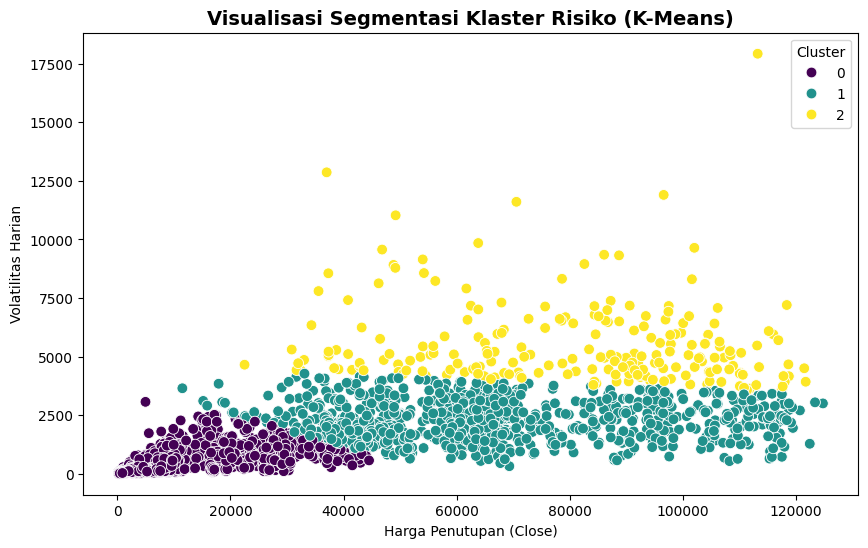

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi Hasil Klaster
plt.figure(figsize=(10, 6))
sns.scatterplot(data=X_train, x='Close', y='Daily_Volatility', hue='Cluster', palette='viridis', s=60)
plt.title('Visualisasi Segmentasi Klaster Risiko (K-Means)', fontsize=14, fontweight='bold')
plt.xlabel('Harga Penutupan (Close)')
plt.ylabel('Volatilitas Harian')
plt.show()

In [ ]:
# Cek distribusi di data training
print("Distribusi Data Training:")
print(X_train['Cluster'].value_counts())

# Cek distribusi di data testing
print("\nDistribusi Data Testing:")
print(X_test['Cluster'].value_counts())

Distribusi Data Training:
Cluster
0    2313
1     890
2     221
Name: count, dtype: int64

Distribusi Data Testing:
Cluster
0    576
1    228
2     52
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import silhouette_score

# Menghitung Silhouette Score
sil_score = silhouette_score(X_train_scaled, kmeans.labels_)
print(f"Nilai Silhouette Score: {sil_score:.4f}")

Nilai Silhouette Score: 0.6340
